## 1. Instalacja bibliotek i importy

In [20]:
!pip -q install librosa soundfile matplotlib numpy

In [21]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

In [22]:
SR = 16000          # częstotliwość próbkowania [Hz] — standard w ASR
N_FFT = 512         # długość okna FFT
HOP_LENGTH = 160    # przesunięcie ramki (10 ms przy 16 kHz)
N_MELS = 64         # liczba pasm mel

## 2. Wczytanie bibliotek

In [23]:
from google.colab import files
uploaded = files.upload()

Saving samogloska.wav to samogloska (1).wav
Saving slowo.wav to slowo (1).wav
Saving zdanie.wav to zdanie (1).wav


In [24]:
def wczytaj_audio(sciezka=None):
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr
    # Sygnał syntetyczny: chirp 200 Hz -> 3000 Hz, 2 s
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR

In [25]:
y_samogloska, sr_samogloska = wczytaj_audio('samogloska.wav')
y_slowo, sr_slowo = wczytaj_audio('slowo.wav')
y_zdanie, sr_zdanie = wczytaj_audio('zdanie.wav')

## 3. Odsłuch

In [26]:
def pokaz_audio(y, sr, nazwa):
    print(f"Plik: {nazwa}")
    print(f"Liczba próbek: {len(y)}")
    print(f"Częstotliwość próbkowania: {sr} Hz")
    print(f"Czas trwania: {len(y) / sr:.2f} s\n")
    display(Audio(y, rate=sr))

audio_dict = {
    "samogloska.wav": (y_samogloska, sr_samogloska),
    "slowo.wav": (y_slowo, sr_slowo),
    "zdanie.wav": (y_zdanie, sr_zdanie)
}

# Wyświetlenie informacji i odtwarzaczy dla każdego pliku
for nazwa, (y, sr) in audio_dict.items():
    pokaz_audio(y, sr, nazwa)

Plik: samogloska.wav
Liczba próbek: 27627
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 1.73 s



Plik: slowo.wav
Liczba próbek: 34454
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 2.15 s



Plik: zdanie.wav
Liczba próbek: 41280
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 2.58 s



## 4. Reprezentacje: log-mel i MFCC

In [27]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

## 5. Wizualizacje

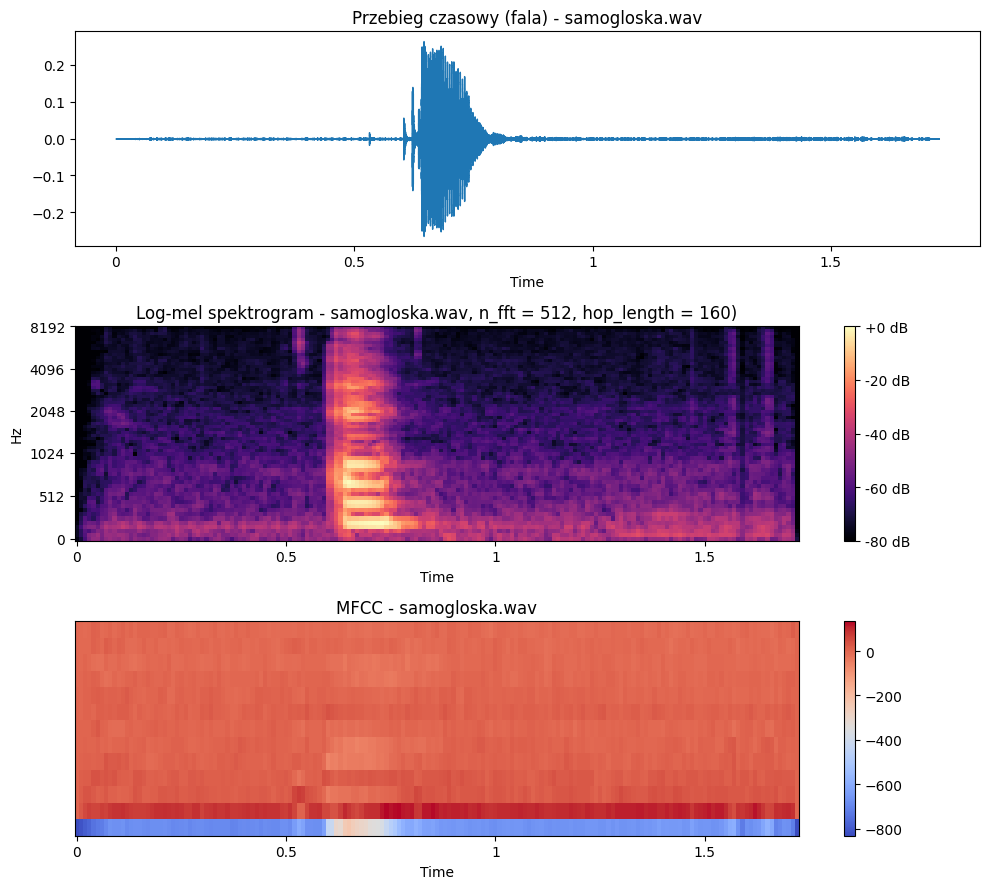

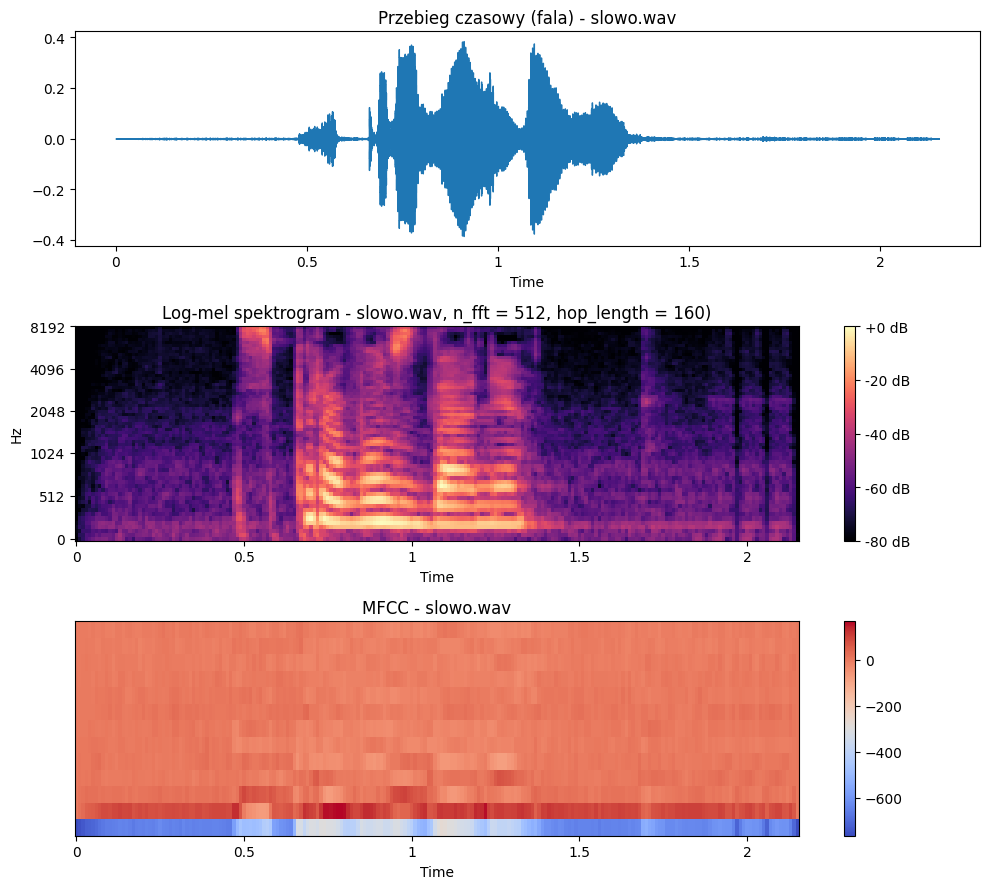

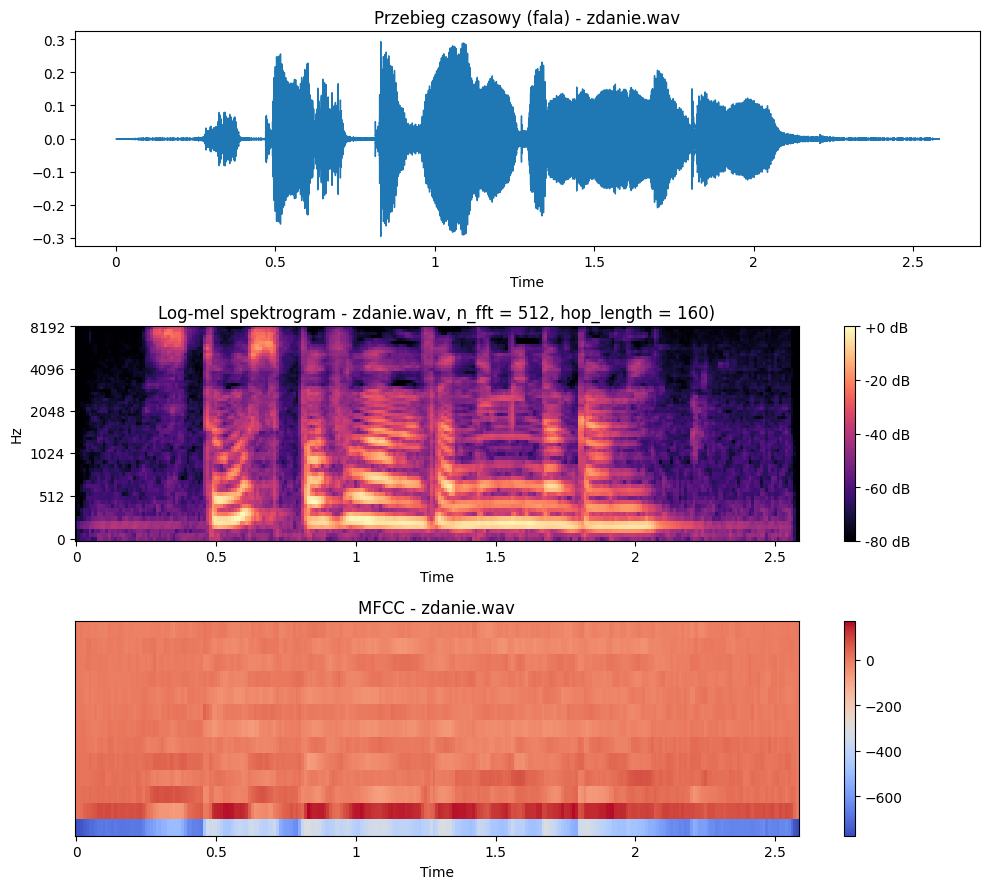

In [28]:
def analiza_audio(y, sr, nazwa, n_fft=N_FFT, hop_length=HOP_LENGTH):
    S_db = log_mel(y, sr, n_fft, hop_length)
    M = mfcc(y, sr)

    fig, ax = plt.subplots(3, 1, figsize=(10, 9))

    # Przebieg czasowy
    librosa.display.waveshow(y, sr=sr, ax=ax[0])
    ax[0].set_title(f"Przebieg czasowy (fala) - {nazwa}")

    # Log-mel spektrogram
    img1 = librosa.display.specshow(
        S_db, sr=sr, hop_length=hop_length, x_axis="time", y_axis="mel", ax=ax[1]
    )
    ax[1].set_title(f"Log-mel spektrogram - {nazwa}, n_fft = {n_fft}, hop_length = {hop_length})")
    fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

    # MFCC
    img2 = librosa.display.specshow(
        M, sr=sr, hop_length=hop_length, x_axis="time", ax=ax[2]
    )
    ax[2].set_title(f"MFCC - {nazwa}")
    fig.colorbar(img2, ax=ax[2])

    plt.tight_layout()
    plt.show()

# Wywołanie dla wszystkich trzech plików
analiza_audio(y_samogloska, sr_samogloska, "samogloska.wav")
analiza_audio(y_slowo, sr_slowo, "slowo.wav")
analiza_audio(y_zdanie, sr_zdanie, "zdanie.wav")

## 6. Modyfikacja wartości n_fft i hop_length

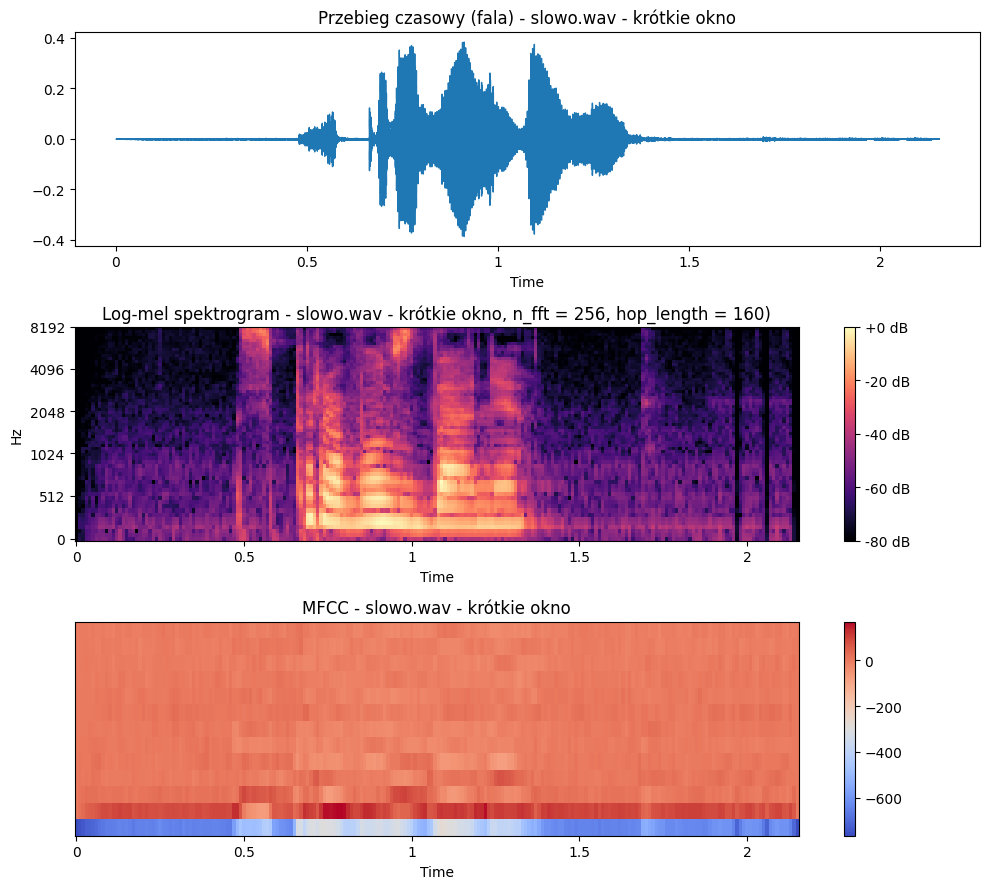

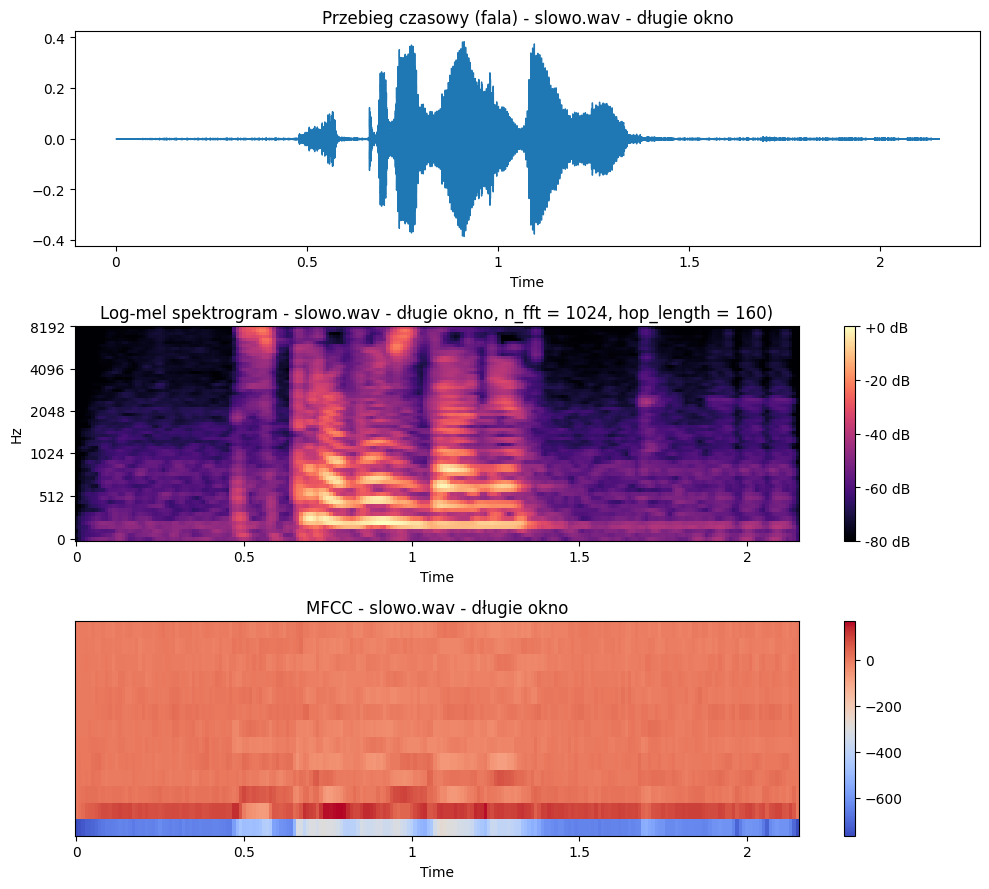

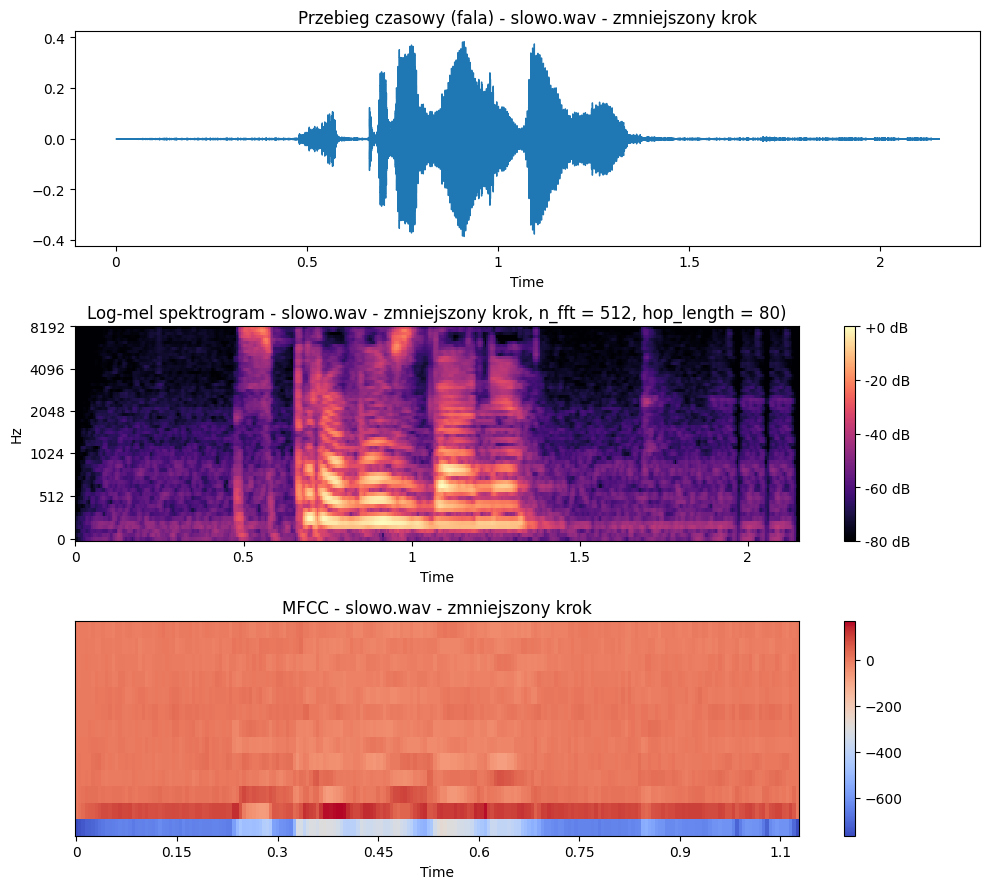

In [29]:
# Krótsze okno- (z 512 na 256)
analiza_audio(y_slowo, sr_slowo, "slowo.wav - krótkie okno", n_fft=256, hop_length=160)

# Dłuższe okno- (z 512 na 1024)
analiza_audio(y_slowo, sr_slowo, "slowo.wav - długie okno", n_fft=1024, hop_length=160)

# Zmniejszony krok (z 160 na 80)
analiza_audio(y_slowo, sr_slowo, "slowo.wav - zmniejszony krok", n_fft=512, hop_length=80)